In [1]:
from itscalledsoccer.client import AmericanSoccerAnalysis
from plotnine import *
from colour import Color
import numpy as np
import pandas as pd

import numpy as np
from collections import defaultdict

import matplotlib.pyplot as plt

from tqdm.notebook import trange, tqdm

asa_client = AmericanSoccerAnalysis()
from sophso import *

In [2]:
def get_games(leagues="nwsl", seasons="2024", status=["FullTime", "PreMatch"]):

    games_df = decorate_team_ids(
        asa_client.get_games(leagues=leagues, seasons=seasons, status=status)
    )
    gxg_df = asa_client.get_game_xgoals(game_ids=list(games_df.game_id))

    games_df = games_df.merge(
        gxg_df[
            [
                "game_id",
                "home_team_xgoals",
                "away_team_xgoals",
                "home_xpoints",
                "away_xpoints",
            ]
        ],
        on="game_id",
        how="left",
    )

    games_df["date_time_utc"] = pd.to_datetime(games_df["date_time_utc"])

    games_df = games_df.sort_values("date_time_utc", ignore_index=True)

    return games_df

In [3]:
decorate_game_ids(get_games(seasons=2026, status="FullTime")).sort_values(
    "date_time_utc", ascending=False
).game_desc.head()

185     LA vs DEN: 2026-09-12
184     KC vs ORL: 2026-09-12
183    LOU vs NJY: 2026-09-11
182     SEA vs SD: 2026-09-07
181    ORL vs HOU: 2026-09-07
Name: game_desc, dtype: object

In [4]:
# def calculate_predictions(games_df, home_points=10, scaling_factor=100):
#     ratings_diff = (
#         games_df["home_rating_pre"] - games_df["away_rating_pre"] + home_points
#     )

#     home_prob = 1 / (1 + 10 ** (-ratings_diff / scaling_factor))
#     games_df["home_prob"] = home_prob

#     return games_df

In [5]:
def calc_points_change(goal_diff, k, expected_result, goal_diff_draw=0):
    if abs(goal_diff) <= 1:
        goal_index = 1
    elif abs(goal_diff) < 3:
        goal_index = (1 + abs(goal_diff)) / 2
    else:
        goal_index = (11 + abs(goal_diff)) / 8

    if abs(goal_diff) <= goal_diff_draw:
        result = 0.5
    else:
        result = max(goal_diff / abs(goal_diff), 0)  # 1 if home wins, 0 if away wins

    return k * goal_index * (result - expected_result)

In [6]:
def elo_learn(
    games_df,
    k=6,
    home_points=11,
    scaling_factor=100.0,
    learn_input="score",
    goal_diff_draw=0.3,
    rating_start=100.0,
):

    games_df = games_df.copy()

    if not "home_rating_pre" in games_df.columns:
        games_df["home_rating_pre"] = rating_start
        games_df["away_rating_pre"] = rating_start
        games_df["home_rating_post"] = rating_start
        games_df["away_rating_post"] = rating_start

    for gid in (
        games_df.sort_values("date_time_utc").query("status=='FullTime'").game_id
    ):

        game_dict = games_df.query(f"game_id == '{gid}'").to_dict(orient="records")[0]

        rating_diff = (
            game_dict["home_rating_pre"] - game_dict["away_rating_pre"] + home_points
        )
        expected_result = 1 / (1 + 10 ** (-rating_diff / scaling_factor))

        if learn_input == "score":
            points_change = calc_points_change(
                goal_diff=(game_dict["home_score"] - game_dict["away_score"]),
                k=k,
                expected_result=expected_result,
                goal_diff_draw=0,
            )
        elif learn_input == "xg":
            points_change = calc_points_change(
                goal_diff=(
                    game_dict["home_team_xgoals"] - game_dict["away_team_xgoals"]
                ),
                k=k,
                expected_result=expected_result,
                goal_diff_draw=goal_diff_draw,
            )
        elif ("xg" in learn_input) and ("score" in learn_input):
            points_change = calc_points_change(
                goal_diff=(game_dict["home_score"] - game_dict["away_score"]),
                k=k,
                expected_result=expected_result,
                goal_diff_draw=0,
            ) + calc_points_change(
                goal_diff=(
                    game_dict["home_team_xgoals"] - game_dict["away_team_xgoals"]
                ),
                k=k,
                expected_result=expected_result,
                goal_diff_draw=goal_diff_draw,
            )
        else:
            raise ("learn_input must be either 'score' or 'xg'")

        game_dict["home_rating_post"] = game_dict["home_rating_pre"] + points_change
        game_dict["away_rating_post"] = game_dict["away_rating_pre"] - points_change

        # set post game rating
        games_df.loc[games_df.game_id == gid, "home_rating_post"] = game_dict[
            "home_rating_post"
        ]
        games_df.loc[games_df.game_id == gid, "away_rating_post"] = game_dict[
            "away_rating_post"
        ]

        # set future pre-game rating

        after_mask = games_df.date_time_utc > game_dict["date_time_utc"]

        # print(
        #     games_df.loc[
        #         after_mask & (games_df.home_team == game_dict["home_team"]),
        #         :,
        #     ]
        # )

        # future home games for today's home team
        games_df.loc[
            after_mask & (games_df.home_team == game_dict["home_team"]),
            "home_rating_pre",
        ] = game_dict["home_rating_post"]
        # future away games for today's home team
        games_df.loc[
            after_mask & (games_df.away_team == game_dict["home_team"]),
            "away_rating_pre",
        ] = game_dict["home_rating_post"]

        # future home games for today's away team
        games_df.loc[
            after_mask & (games_df.home_team == game_dict["away_team"]),
            "home_rating_pre",
        ] = game_dict["away_rating_post"]
        # future away games for today's away team
        games_df.loc[
            after_mask & (games_df.away_team == game_dict["away_team"]),
            "away_rating_pre",
        ] = game_dict["away_rating_post"]

        # update match probabilities

        ratings_diff = (
            games_df["home_rating_pre"] - games_df["away_rating_pre"] + home_points
        )

        # home_prob = 1 / (1 + 10 ** (-ratings_diff / scaling_factor))
        # games_df["home_prob"] = home_prob

        # include draws
        draw_k = 0.7

        home_win_prob = 10 ** (ratings_diff / scaling_factor) / (
            10 ** (-ratings_diff / scaling_factor)
            + draw_k
            + 10 ** (ratings_diff / scaling_factor)
        )
        away_win_prob = 10 ** (-ratings_diff / scaling_factor) / (
            10 ** (-ratings_diff / scaling_factor)
            + draw_k
            + 10 ** (ratings_diff / scaling_factor)
        )
        draw_prob = draw_k * (home_win_prob * away_win_prob) ** 0.5
        games_df["home_win_prob"] = home_win_prob
        games_df["draw_prob"] = draw_prob

    return games_df

In [7]:
def plot_elo_over_time(games_df, **elo_params):

    # games_df = get_games(leagues="nwsl", seasons="2025")

    # compute ratings
    games_df = elo_learn(games_df, **elo_params).query("status=='FullTime'")

    # build history plot based on outcomes
    elo_history_df = pd.concat(
        [
            games_df[["home_team", "date_time_utc", "home_rating_post"]].rename(
                columns={"home_team": "team", "home_rating_post": "rating"}
            ),
            games_df[["away_team", "date_time_utc", "away_rating_post"]].rename(
                columns={"away_team": "team", "away_rating_post": "rating"}
            ),
        ],
        ignore_index=True,
    ).sort_values("date_time_utc", ignore_index=True)

    # set order of teams
    elo_last_rating = elo_history_df.groupby("team").rating.last()
    ordered_teams = list(elo_last_rating.sort_values(ascending=False).index)
    elo_history_df.team = pd.Categorical(
        elo_history_df.team,
        categories=ordered_teams,
    )

    if elo_params["learn_input"] == "score":
        rating_desc = "scoreline-based"
    elif elo_params["learn_input"] == "xg":
        rating_desc = "xG-based"
    elif elo_params["learn_input"] == "xg+score":
        rating_desc = "xG+score-based"

    return (
        (
            ggplot(
                elo_history_df,
                aes(x="date_time_utc", y="rating", color="team", fill="team"),
            )
            + geom_line(size=1)
            + geom_point(stroke=0.5, size=3)
            + scale_color_manual(nwsl_primary_colors)
            + scale_fill_manual(nwsl_secondary_colors)
            + labs(
                y="Rating",
                x="Date",
                title=f"Elo Rating over time for {rating_desc} model: NWSL {games_df.season_name.max()}",
                caption="""Model using data from American Soccer Analysis
Model inspiration from @trevorl.bsky.social""",
            )
            + theme_minimal()
            + theme(
                figure_size=(12, 6),
                # axis_text_x=element_text(angle=90),
            )
        ),
        games_df,
    )

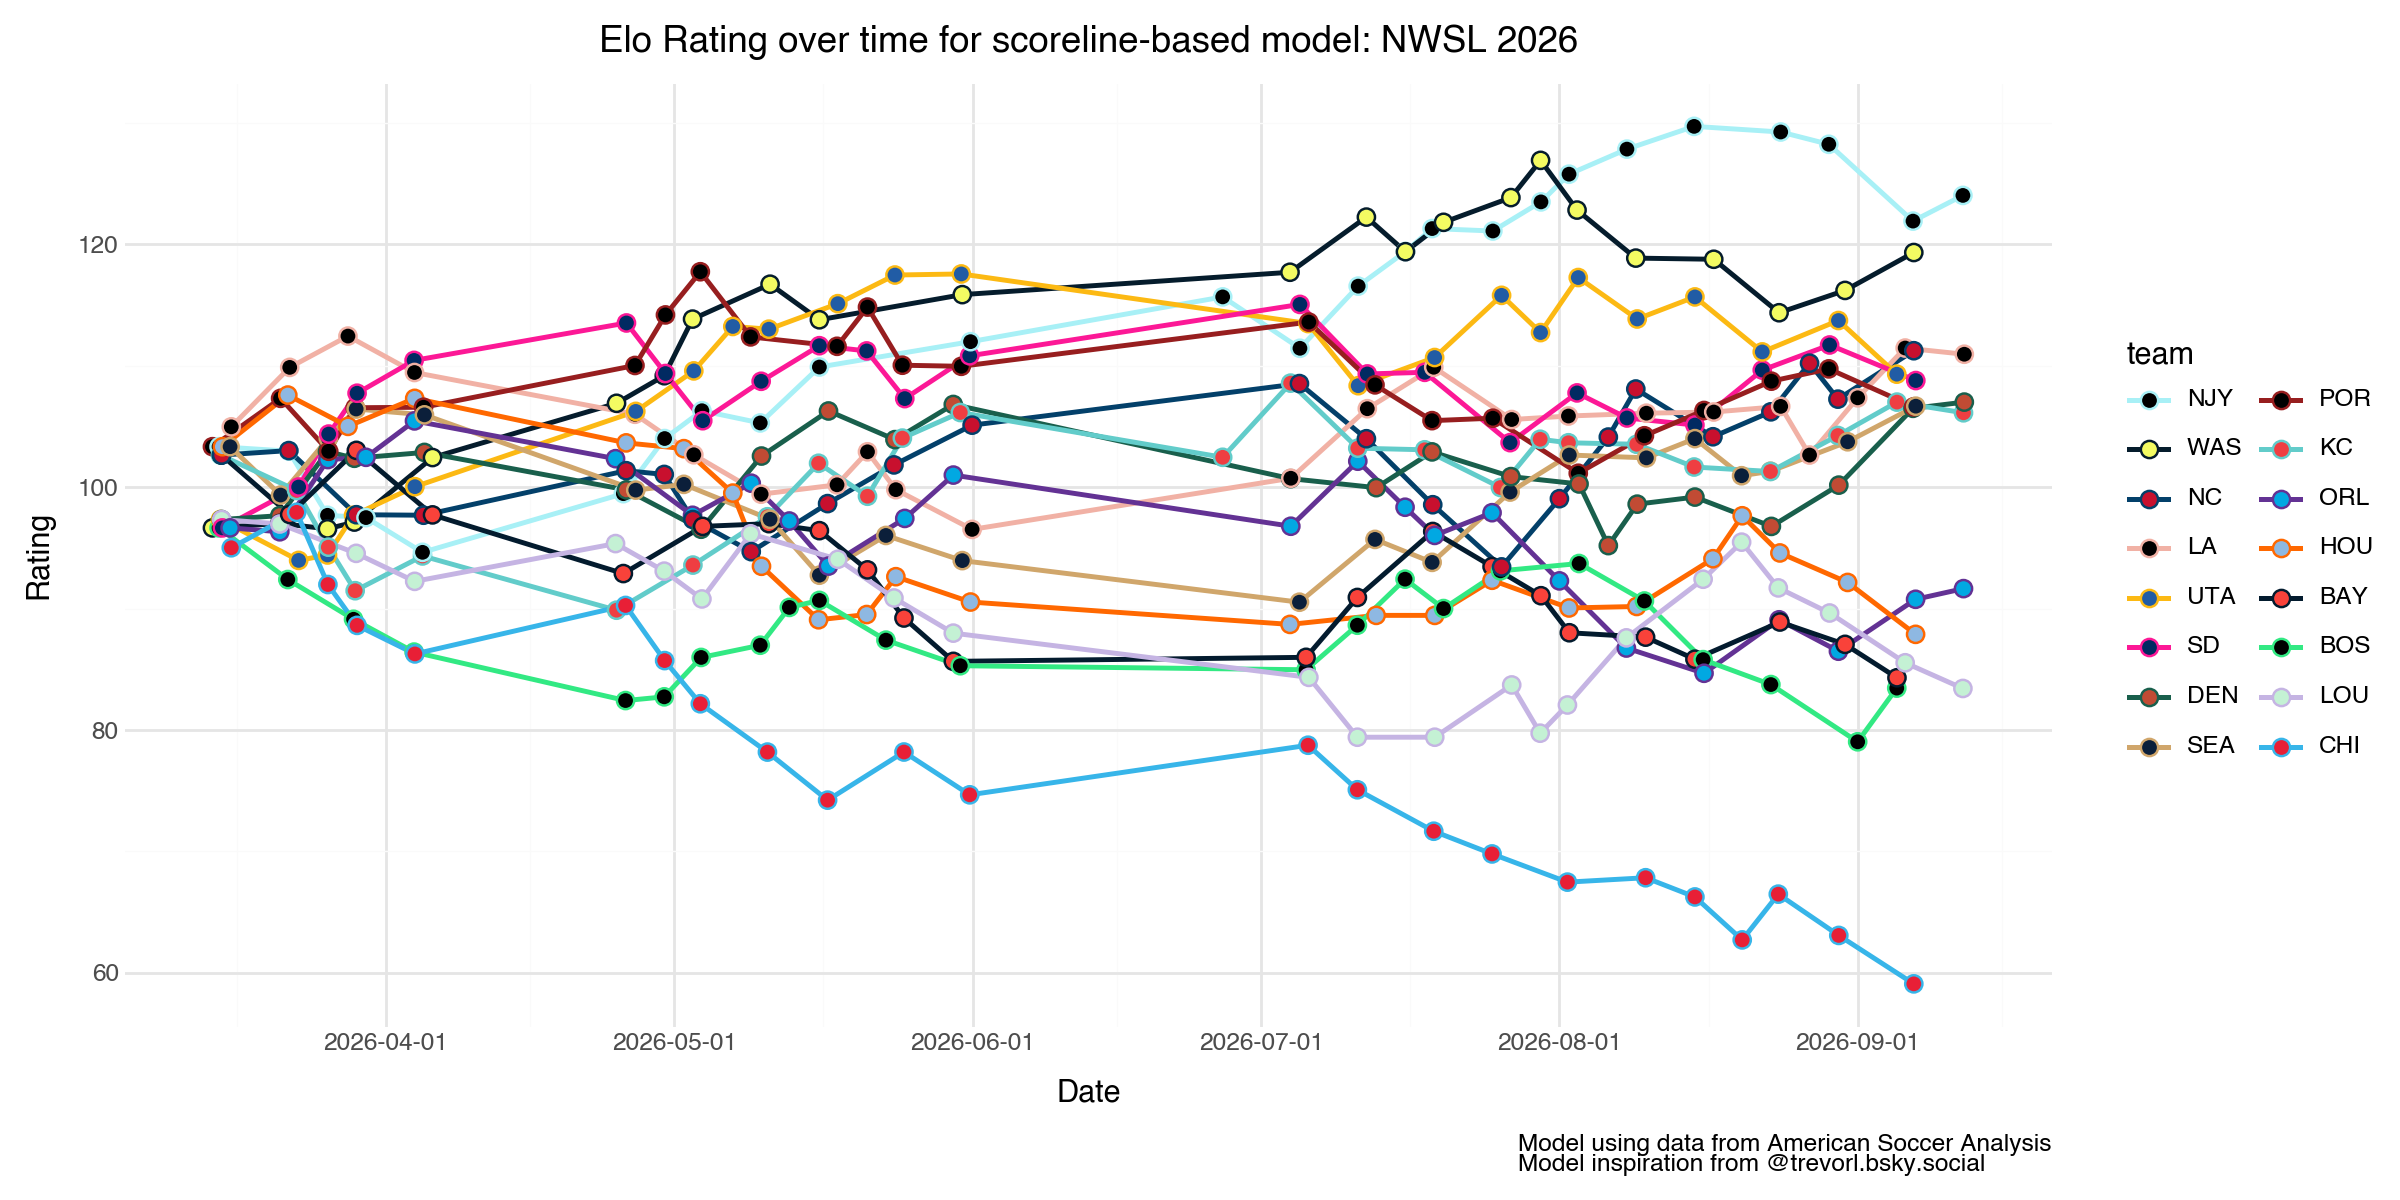

In [8]:
params = dict(
    home_points=10, k=6, scaling_factor=100, learn_input="score", goal_diff_draw=0.03
)

games_df = get_games(leagues="nwsl", seasons="2026")


plot, games_df = plot_elo_over_time(games_df, **params)
plot

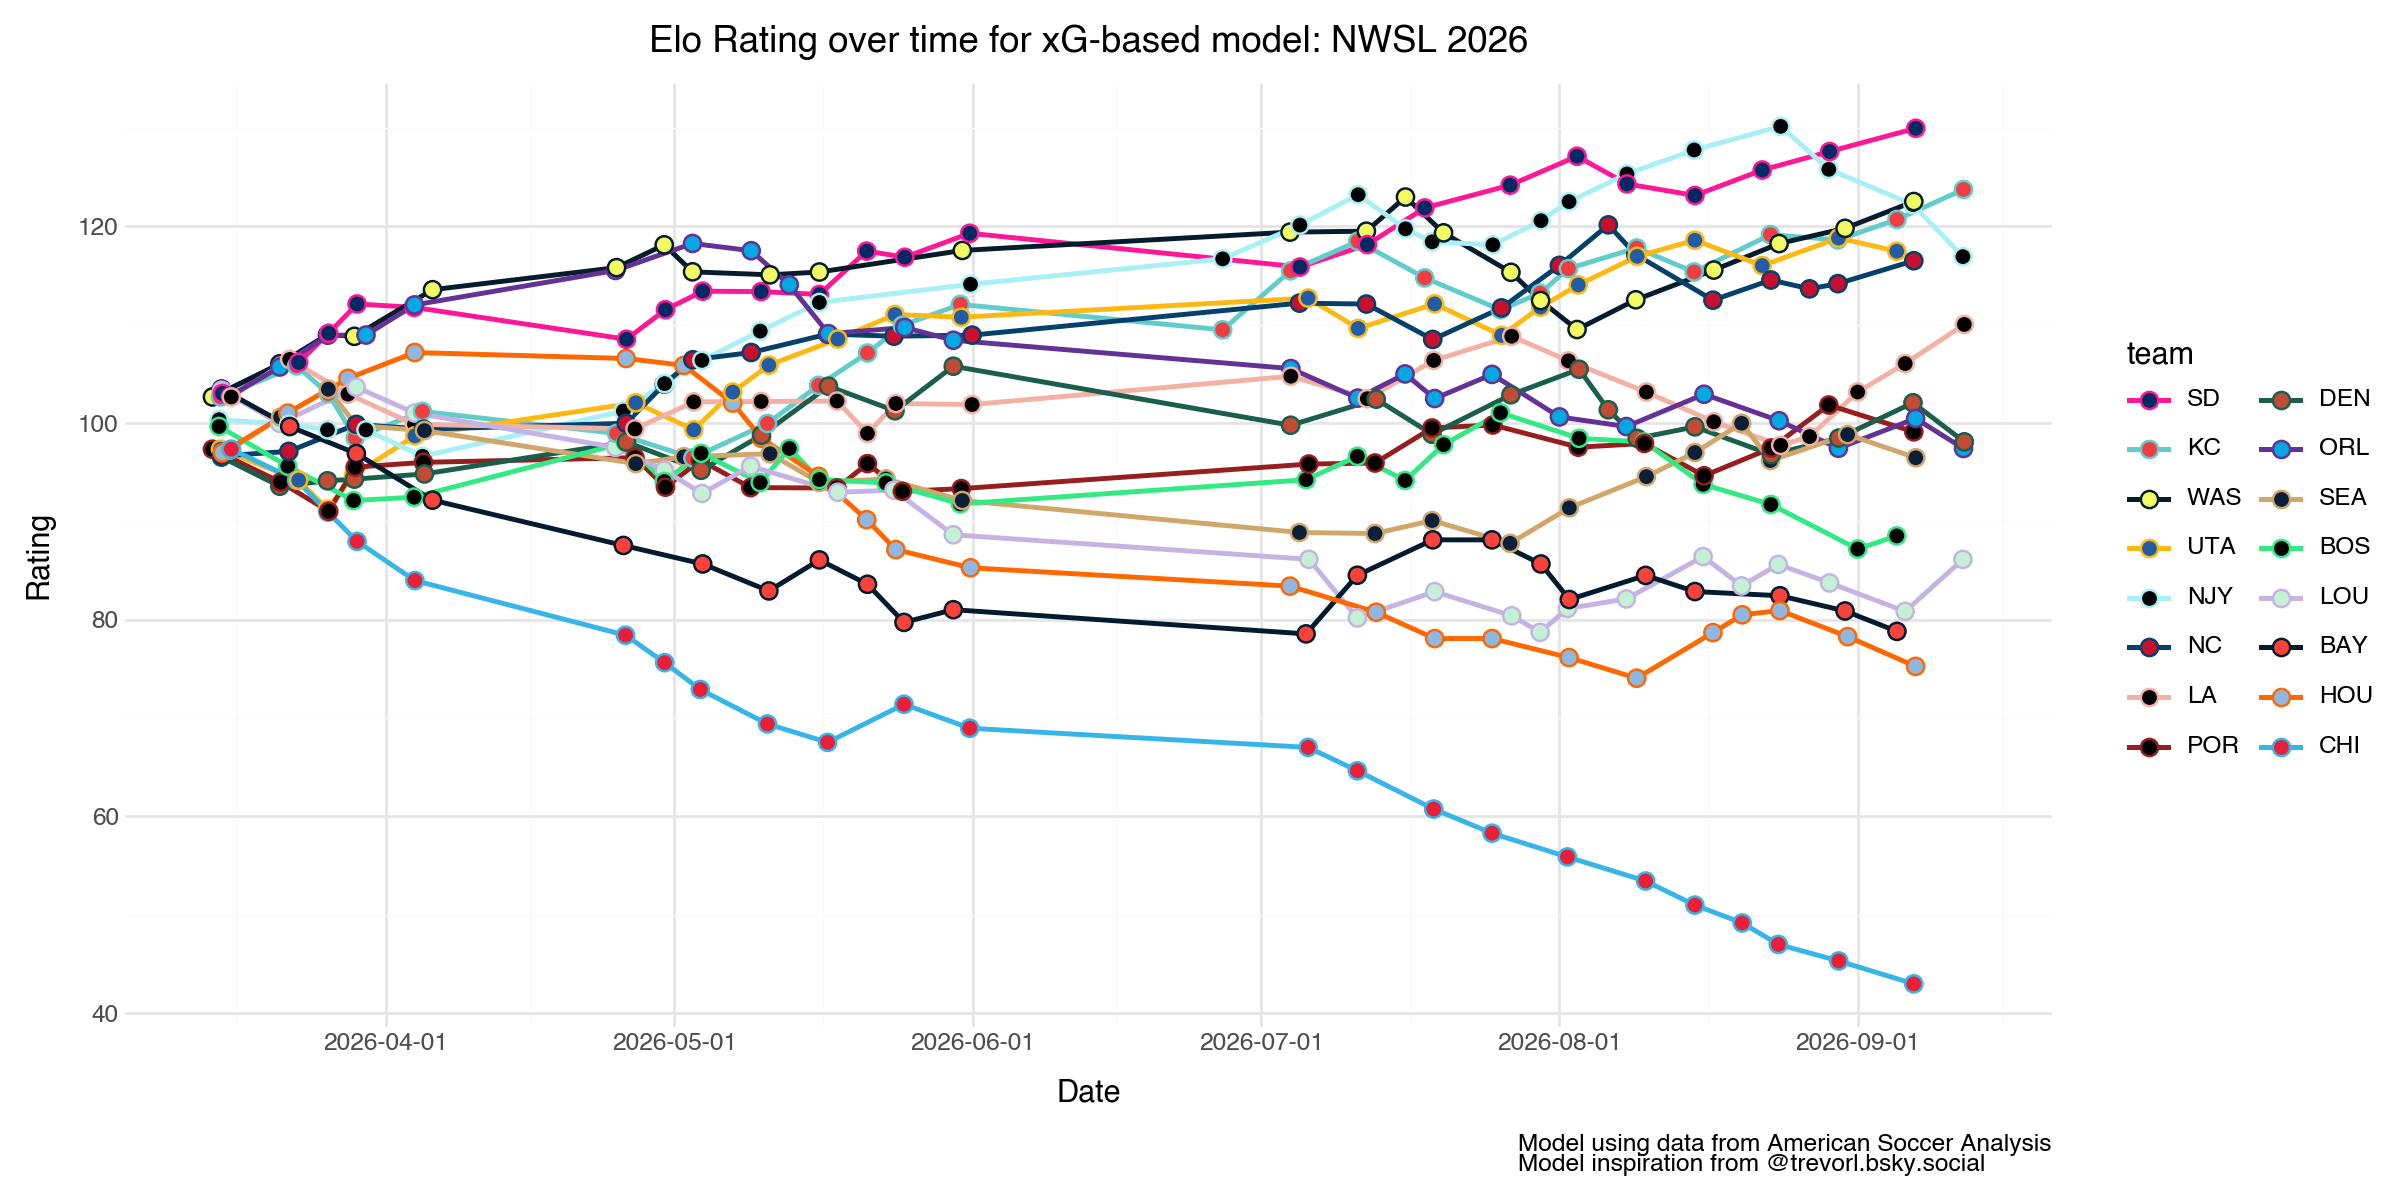

In [9]:
params = dict(
    home_points=10, k=6, scaling_factor=100, learn_input="xg", goal_diff_draw=0.3
)

games_df = get_games(leagues="nwsl", seasons="2026")

plot_elo_over_time(games_df, **params)[0]

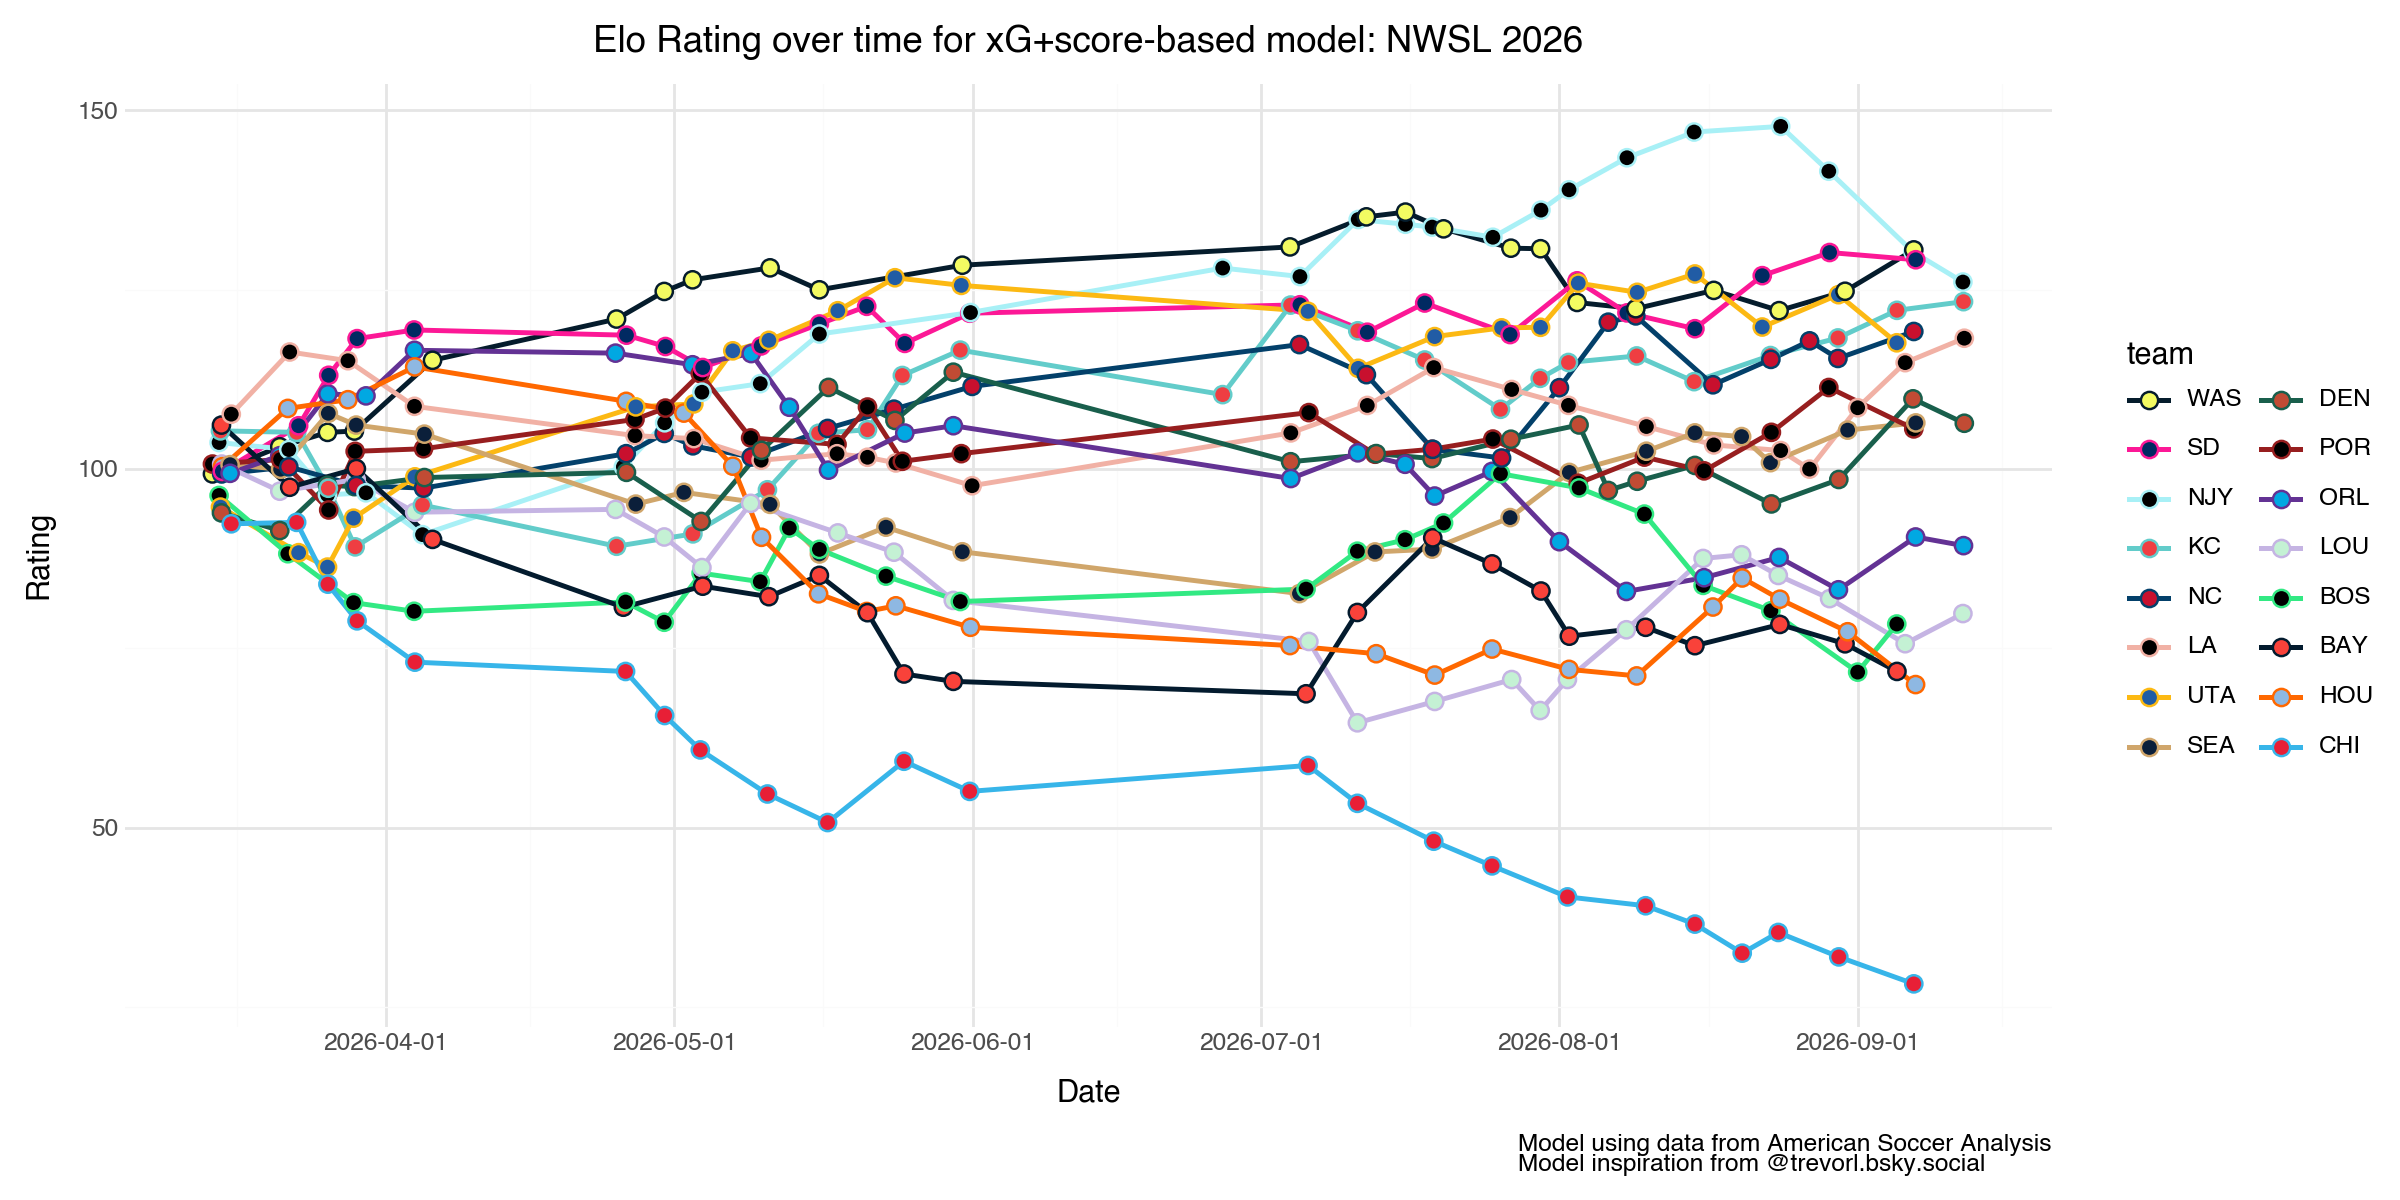

In [10]:
params = dict(
    home_points=10,
    k=6,
    scaling_factor=100,
    learn_input="xg+score",
    goal_diff_draw=0.3,
)

games_df = get_games(leagues="nwsl", seasons="2026")

plot_elo_over_time(games_df, **params)[0]

# Simulate a season!


In [11]:
import numpy as np

rng = np.random.default_rng()

In [12]:
def simulate_season(games_df, num_runs=100, return_history=False):

    prematch_mask = games_df.status == "PreMatch"
    num_games = games_df[prematch_mask].shape[0]

    df_list = []

    if return_history:
        history_list = []

    for run_i in range(num_runs):

        games_df["home_points"] = 0
        games_df["away_points"] = 0
        games_df["home_win"] = 0
        games_df["away_win"] = 0

        random_roll = rng.random((num_games))

        hw_mask = random_roll < games_df.loc[prematch_mask, "home_win_prob"]
        draw_mask = (~hw_mask) & (
            random_roll
            < (
                games_df.loc[prematch_mask, "home_win_prob"]
                + games_df.loc[prematch_mask, "draw_prob"]
            )
        )

        hl_mask = (~hw_mask) & (~draw_mask)

        # assert np.all(hw_mask + draw_mask + hl_mask)

        games_df.loc[prematch_mask & hw_mask, "home_score"] = 1
        games_df.loc[prematch_mask & hw_mask, "away_score"] = 0
        games_df.loc[prematch_mask & draw_mask, "home_score"] = 0
        games_df.loc[prematch_mask & draw_mask, "away_score"] = 0
        games_df.loc[prematch_mask & hl_mask, "home_score"] = 0
        games_df.loc[prematch_mask & hl_mask, "away_score"] = 1

        # draws
        draw_mask = games_df.home_score == games_df.away_score
        games_df.loc[draw_mask, "home_points"] = 1
        games_df.loc[draw_mask, "away_points"] = 1

        # home wins
        hw_mask = games_df.home_score > games_df.away_score
        games_df.loc[hw_mask, "home_points"] = 3
        games_df.loc[hw_mask, "away_points"] = 0
        games_df.loc[hw_mask, "home_win"] = 1

        # away wins
        aw_mask = games_df.home_score < games_df.away_score
        games_df.loc[aw_mask, "home_points"] = 0
        games_df.loc[aw_mask, "away_points"] = 3
        games_df.loc[aw_mask, "away_win"] = 1

        run_df = (
            (
                games_df.groupby("home_team").agg(
                    points=pd.NamedAgg(column="home_points", aggfunc="sum"),
                    goals_for=pd.NamedAgg(column="home_score", aggfunc="sum"),
                    wins=pd.NamedAgg(column="home_win", aggfunc="sum"),
                    goals_against=pd.NamedAgg(column="away_score", aggfunc="sum"),
                )
                + games_df.groupby("away_team").agg(
                    points=pd.NamedAgg(column="away_points", aggfunc="sum"),
                    goals_for=pd.NamedAgg(column="away_score", aggfunc="sum"),
                    wins=pd.NamedAgg(column="away_win", aggfunc="sum"),
                    goals_against=pd.NamedAgg(column="home_score", aggfunc="sum"),
                )
            )
            .reset_index()
            .rename(columns={"home_team": "team"})
        )

        run_df["run_index"] = run_i

        df_list.append(run_df)
        if return_history:
            games_history = games_df.copy()
            games_history["run_index"] = run_i

            history_list.append(games_history)

    sim_df = pd.concat(df_list, ignore_index=True)

    if return_history:
        history_df = pd.concat(history_list, ignore_index=True)
        return sim_df, history_df

    return sim_df

In [13]:
def gen_projected_points_over_time(games_df, num_runs=100, **elo_params):

    last_matchday = games_df.query("status=='FullTime'").matchday.max()

    proj_df_list = []

    for md_i in trange(1, last_matchday + 1):
        sim_games = games_df.copy()

        # set later matchdays to PreMatch
        sim_games.loc[sim_games.matchday > md_i, "status"] = "PreMatch"

        sim_games = elo_learn(sim_games, **elo_params)

        proj_df = simulate_season(sim_games, num_runs=num_runs)
        proj_df["matchday"] = md_i
        proj_df_list.append(proj_df)

    return pd.concat(proj_df_list)

In [14]:
# params = dict(
#     home_points=10,
#     k=6,
#     scaling_factor=100,
#     learn_input="xg+score",
#     goal_diff_draw=0.3,
# )

# games_df = get_games(leagues="nwsl", seasons="2025").query(
#     "(matchday == 19) | (matchday == 20)"
# )

# games_df = elo_learn(games_df, **params)

# proj_df = simulate_season(games_df, runs=2)

In [15]:
# (proj_df.points - proj_df.wins * 3).value_counts()

In [16]:
# proj_df["rank"].value_counts()

In [17]:
# proj_df

In [18]:
def plot_projected_points_over_time(games_df, num_runs=100, **elo_params):

    proj_df = gen_projected_points_over_time(games_df, num_runs=num_runs, **elo_params)
    plot_df = proj_df.groupby(["team", "matchday"]).points.mean().reset_index()

    # set order of teams
    last_pp = plot_df.groupby("team").points.last()
    ordered_teams = list(last_pp.sort_values(ascending=False).index)
    plot_df.team = pd.Categorical(
        plot_df.team,
        categories=ordered_teams,
    )

    plot = (
        ggplot(
            plot_df,
            aes(x="matchday", y="points", color="team", fill="team"),
        )
        + geom_line(size=1)
        + geom_point(stroke=0.5, size=3)
        + scale_color_manual(nwsl_primary_colors)
        + scale_fill_manual(nwsl_secondary_colors)
        + labs(
            y="Projected Points",
            x="Match week",
            title=f"Change in end-of-season projected points over time",
            caption="""xG+score informed Elo model.
Trained on provided by American Soccer Analysis
Model inspiration from @trevorl.bsky.social""",
        )
        + theme_minimal()
        + theme(
            figure_size=(12, 6),
            # axis_text_x=element_text(angle=90),
        )
    )

    return plot, proj_df

In [19]:
# proj_df.groupby(["team", "matchday"]).points.median().reset_index()

  0%|          | 0/21 [00:00<?, ?it/s]

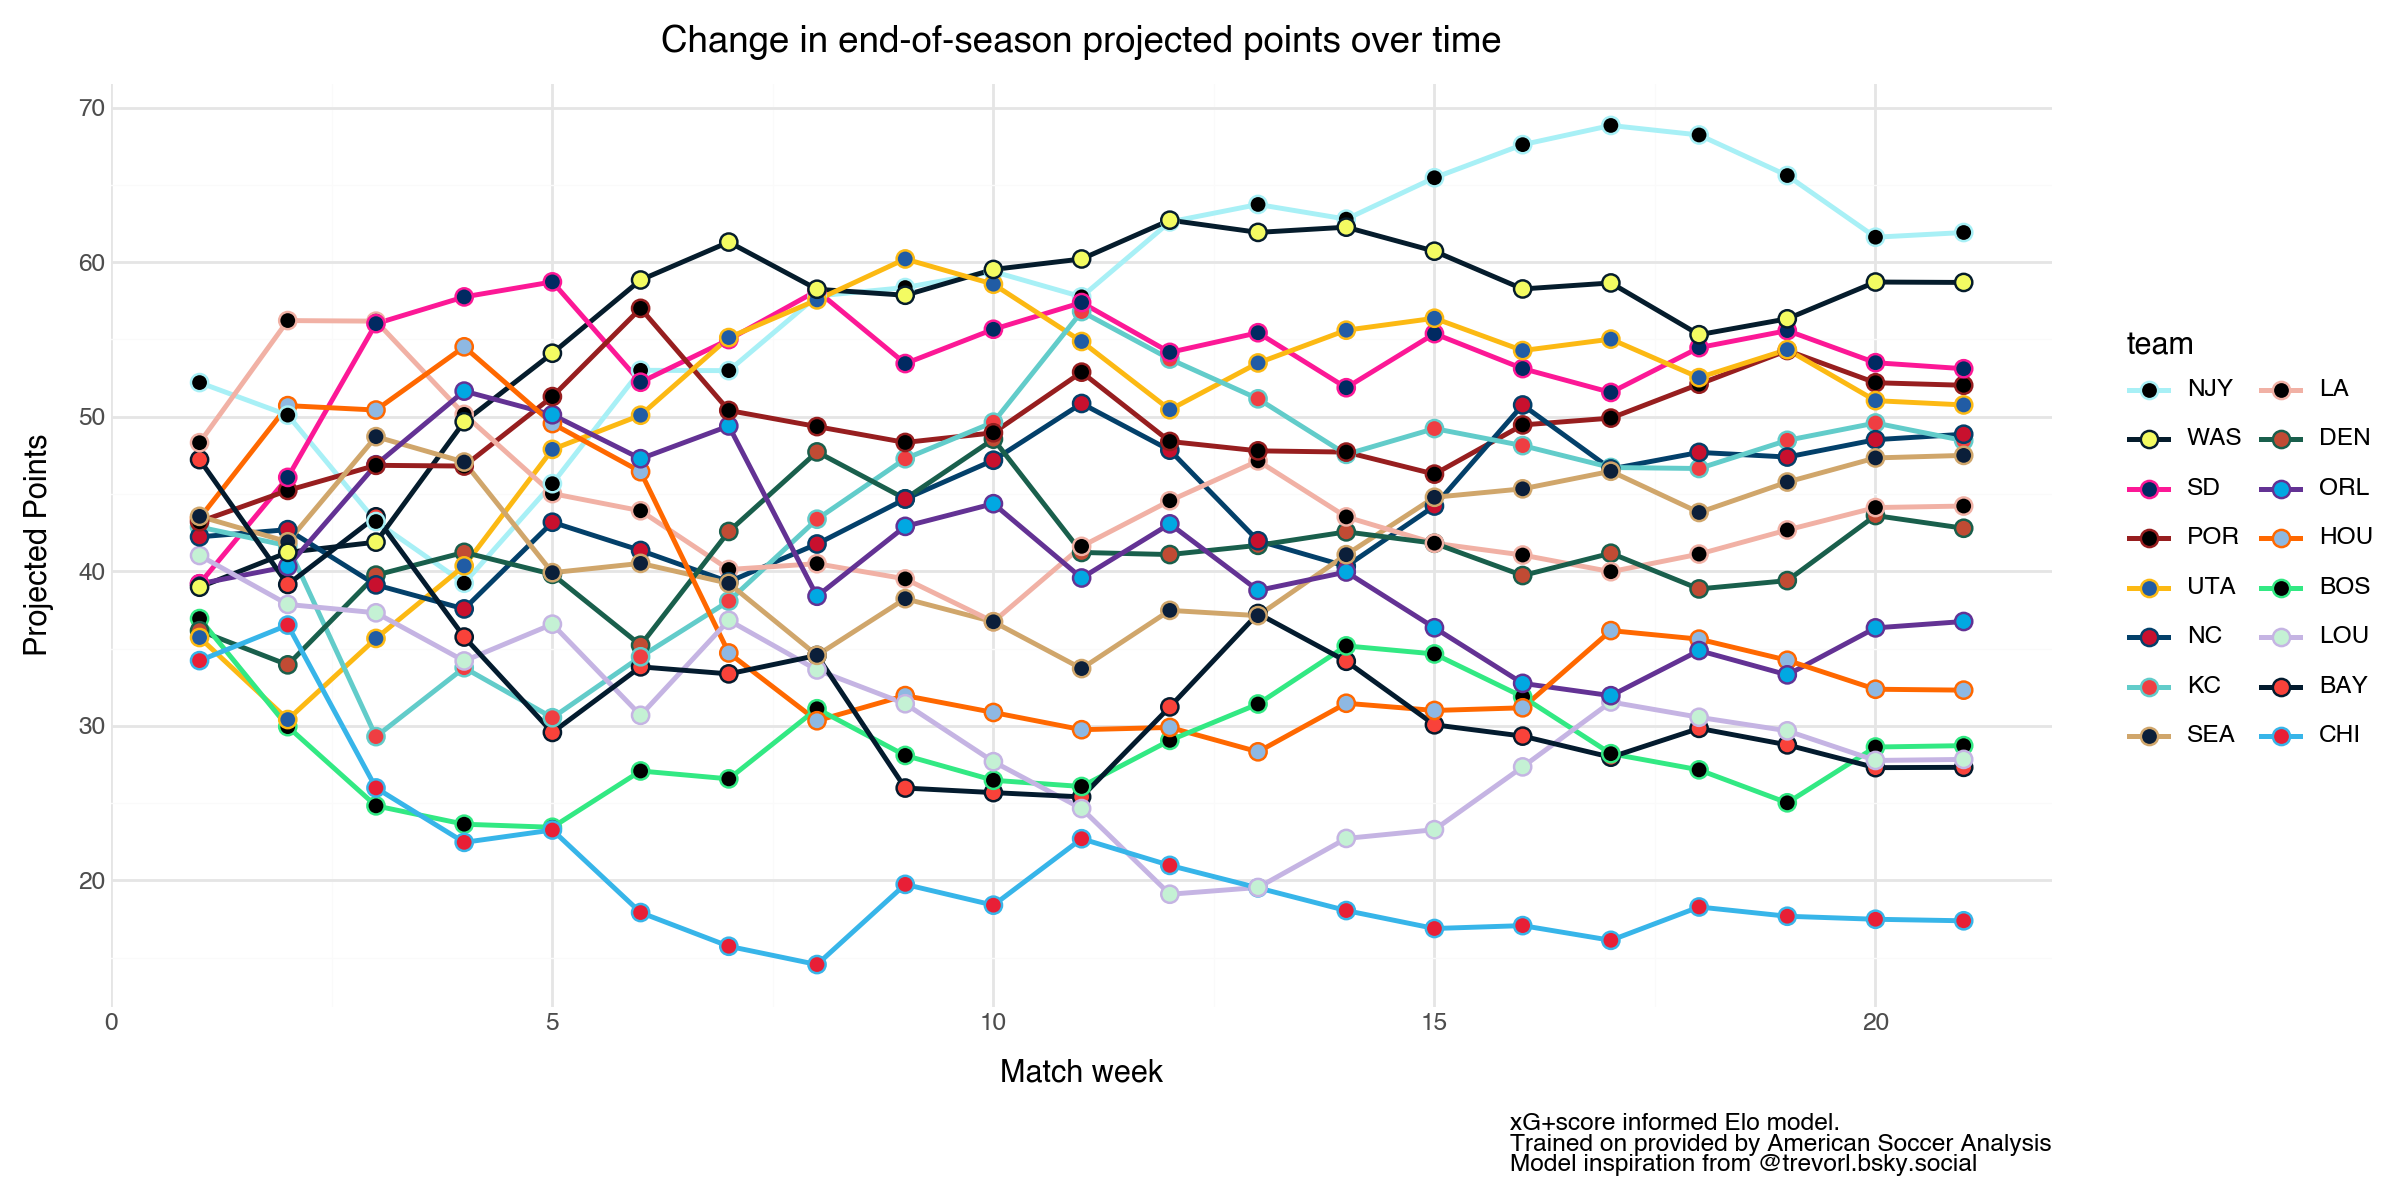

In [20]:
params = dict(
    home_points=10, k=6, scaling_factor=100, learn_input="xg+score", goal_diff_draw=0.3
)

games_df = get_games(leagues="nwsl", seasons="2026")


plot, proj_df = plot_projected_points_over_time(games_df, num_runs=1000, **params)

plot

In [21]:
## test cell for just generating the simulation runs
# params = dict(
#     home_points=12, k=8, scaling_factor=100, learn_input="xg+score", goal_diff_draw=0.3
# )


# proj_df = gen_projected_points_over_time(games_df, num_runs=100, **params)

proj_df["goal_difference"] = proj_df["goals_for"] - proj_df["goals_against"]

# shuffle with new index
proj_df = proj_df.sample(frac=1).reset_index(drop=True)

In [22]:
def nwsl_rank_func(input_df):
    """function that sorts a dataframe of teams based on NWSL playoff criteria"""

    return (
        input_df[["points", "goal_difference", "wins", "goals_for"]]
        .apply(tuple, axis=1)
        .rank(
            method="first",
            ascending=False,
        )
        .astype(int)
    )


def decorate_rank(input_df):

    input_df["rank"] = input_df.groupby(["matchday", "run_index"], group_keys=False)[
        ["points", "goal_difference", "wins", "goals_for"]
    ].apply(nwsl_rank_func)

    input_df["in_playoff"] = (input_df["rank"] <= 8).astype(int)

    return input_df


proj_df = decorate_rank(proj_df)

In [23]:
pretty_df = (
    proj_df.groupby(["team", "matchday"])[["in_playoff", "points"]].mean().reset_index()
)

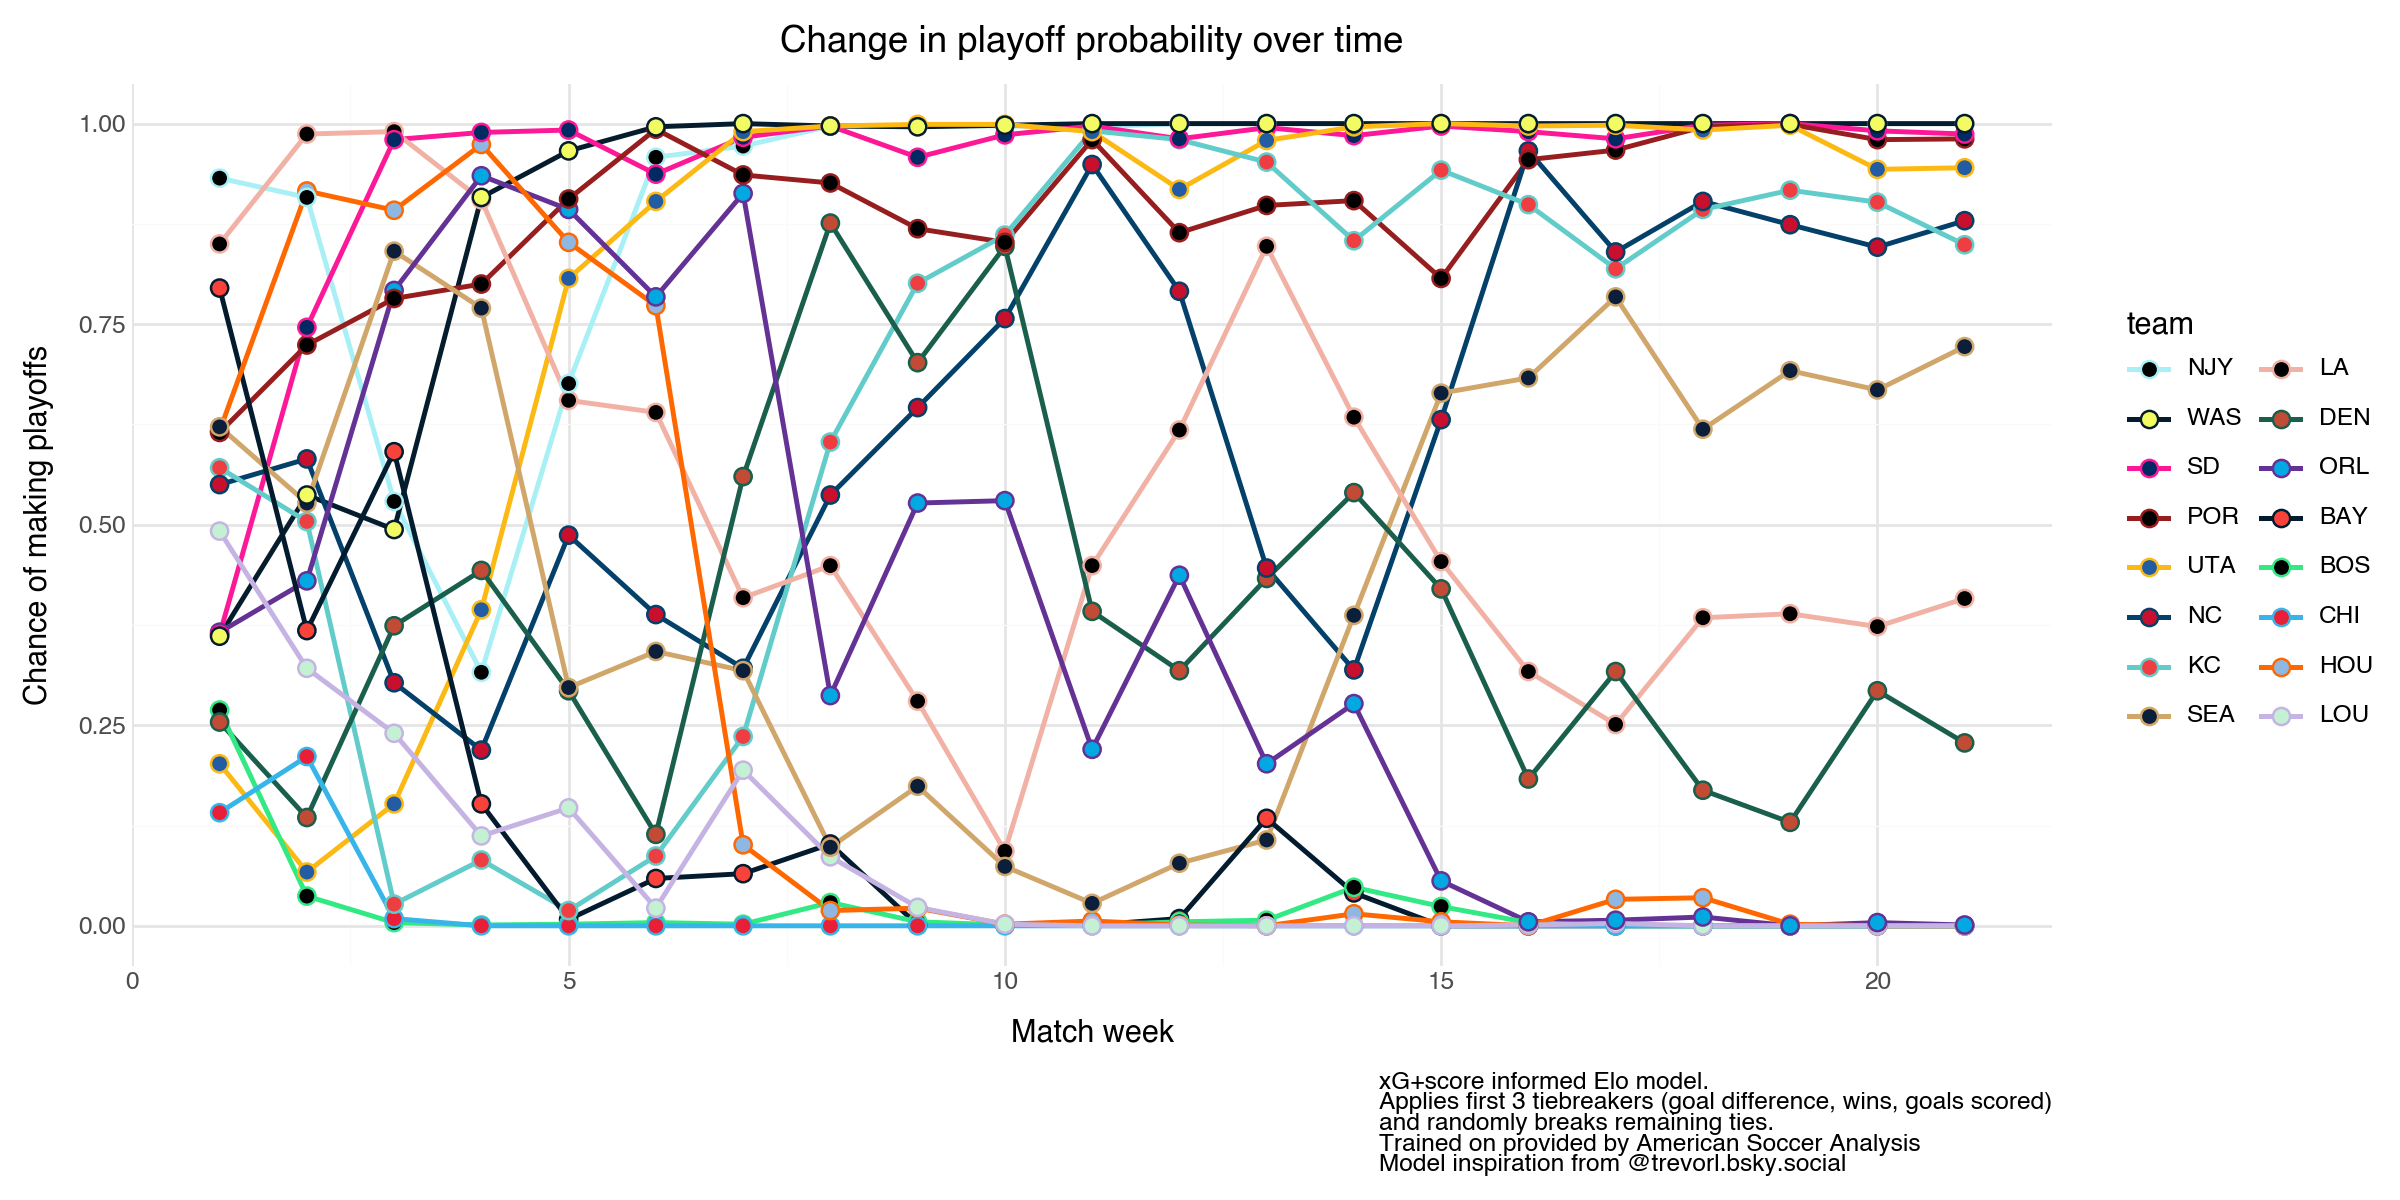

In [24]:
# set order of teams
last_pp = pretty_df.groupby("team").in_playoff.last()
ordered_teams = list(last_pp.sort_values(ascending=False).index)
pretty_df.team = pd.Categorical(
    pretty_df.team,
    categories=ordered_teams,
)

(
    ggplot(
        pretty_df,
        aes(x="matchday", y="in_playoff", color="team", fill="team"),
    )
    + geom_line(size=1)
    + geom_point(stroke=0.5, size=3)
    + scale_color_manual(nwsl_primary_colors)
    + scale_fill_manual(nwsl_secondary_colors)
    + theme_minimal()
    + theme(
        figure_size=(12, 6),
    )
    + labs(
        y="Chance of making playoffs",
        x="Match week",
        title=f"Change in playoff probability over time",
        caption="""xG+score informed Elo model.
Applies first 3 tiebreakers (goal difference, wins, goals scored)
and randomly breaks remaining ties.
Trained on provided by American Soccer Analysis
Model inspiration from @trevorl.bsky.social""",
    )
)

In [25]:
pretty_df

,team,matchday,in_playoff,points
0,BAY,1,0.795,47.223
1,BAY,2,0.368,39.145
2,BAY,3,0.591,43.525
3,BAY,4,0.152,35.746
4,BAY,5,0.008,29.572
...,...,...,...,...
331,WAS,17,1.000,58.657
332,WAS,18,1.000,55.308
333,WAS,19,1.000,56.336
334,WAS,20,1.000,58.716


In [26]:
last_matchday = games_df.query("status=='FullTime'").matchday.max()

pretty_table = pretty_df.query(f"matchday == {last_matchday}")[
    ["team", "points", "in_playoff"]
].rename(columns={"points": "projected points", "in_playoff": "in playoffs"})


lw_projp = pretty_df.query(f"matchday == {last_matchday-1}")[["team", "points"]].rename(
    columns={"points": "last week points"}
)

pretty_table = pretty_table.merge(lw_projp, on="team")

pretty_table["projected points change"] = (
    pretty_table["projected points"] - pretty_table["last week points"]
)

pretty_table

,team,projected points,in playoffs,last week points,projected points change
0,BAY,27.315,0.000,27.294,0.021
1,BOS,28.718,0.000,28.628,0.090
2,CHI,17.385,0.000,17.484,-0.099
3,DEN,42.783,0.228,43.607,-0.824
4,HOU,32.309,0.000,32.368,-0.059
5,KC,48.454,0.849,49.595,-1.141
6,LA,44.221,0.408,44.123,0.098
7,LOU,27.827,0.000,27.760,0.067
8,NC,48.868,0.879,48.514,0.354
9,NJY,61.920,1.000,61.616,0.304


In [27]:
pretty_table.sort_values("projected points", ascending=False).style.format(
    {"in playoffs": "{:.1%}", "projected points change": "{:+.1f}"}, precision=1
).format_index(lambda x: x + 1).hide(["last week points"], axis=1).background_gradient(
    # cmap="PuOr"
).set_caption(
    f"End of season projected points after matchday {last_matchday}"
).hide()

team,projected points,in playoffs,projected points change
NJY,61.9,100.0%,+0.3
WAS,58.7,100.0%,-0.0
SD,53.1,98.7%,-0.4
POR,52.0,98.1%,-0.2
UTA,50.8,94.5%,-0.3
NC,48.9,87.9%,+0.4
KC,48.5,84.9%,-1.1
SEA,47.5,72.2%,+0.2
LA,44.2,40.8%,+0.1
DEN,42.8,22.8%,-0.8


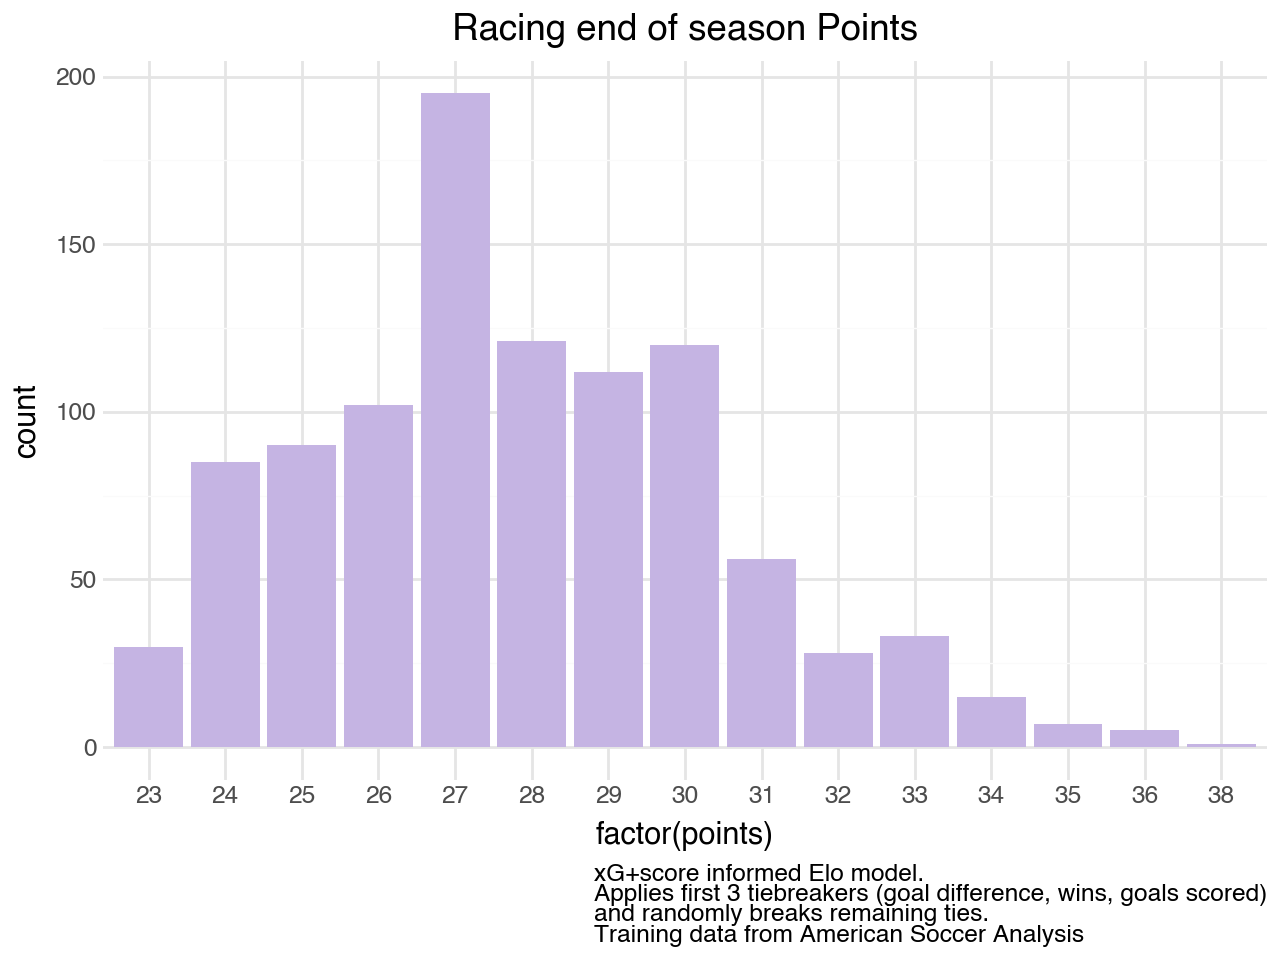

In [28]:
(
    ggplot(
        proj_df.query(f"(team == 'LOU') & (matchday == {last_matchday})"),
        aes(x="factor(points)", fill="team"),
    )
    + geom_bar()
    + scale_fill_manual(nwsl_primary_colors, guide=None)
    + theme_minimal()
    + labs(
        # y="Chance of making playoffs",
        # x="Matchday",
        title=f"Racing end of season Points",
        caption="""xG+score informed Elo model.
Applies first 3 tiebreakers (goal difference, wins, goals scored)
and randomly breaks remaining ties.
Training data from American Soccer Analysis""",
    )
)

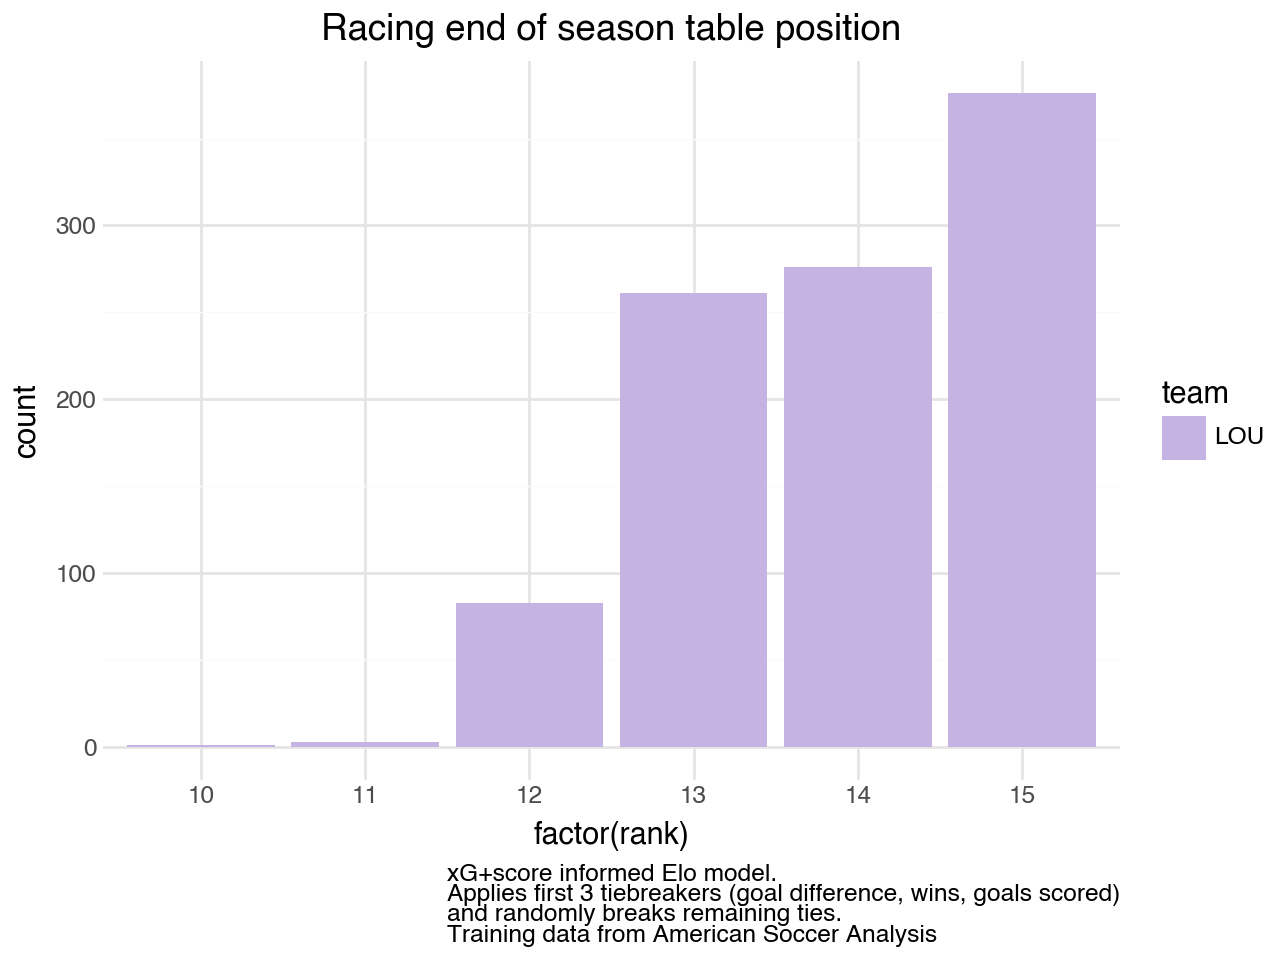

In [29]:
(
    ggplot(
        proj_df.query(f"(team == 'LOU') & (matchday == {last_matchday})"),
        aes(x="factor(rank)", fill="team"),
    )
    + geom_bar()
    + scale_fill_manual(nwsl_primary_colors)
    + theme_minimal()
    # + scale_x_reverse()
    + labs(
        # y="Chance of making playoffs",
        # x="Matchday",
        title=f"Racing end of season table position",
        caption="""xG+score informed Elo model.
Applies first 3 tiebreakers (goal difference, wins, goals scored)
and randomly breaks remaining ties.
Training data from American Soccer Analysis""",
    )
)

In [30]:
proj_df.team = pd.Categorical(
    proj_df.team,
    categories=pretty_table.sort_values(
        ["in playoffs", "projected points"], ascending=False
    ).team.to_list(),
)

/var/folders/42/c1xq4jg10213hqzzpdz5xkjm0000gn/T/ipykernel_24903/4094167725.py:3: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.


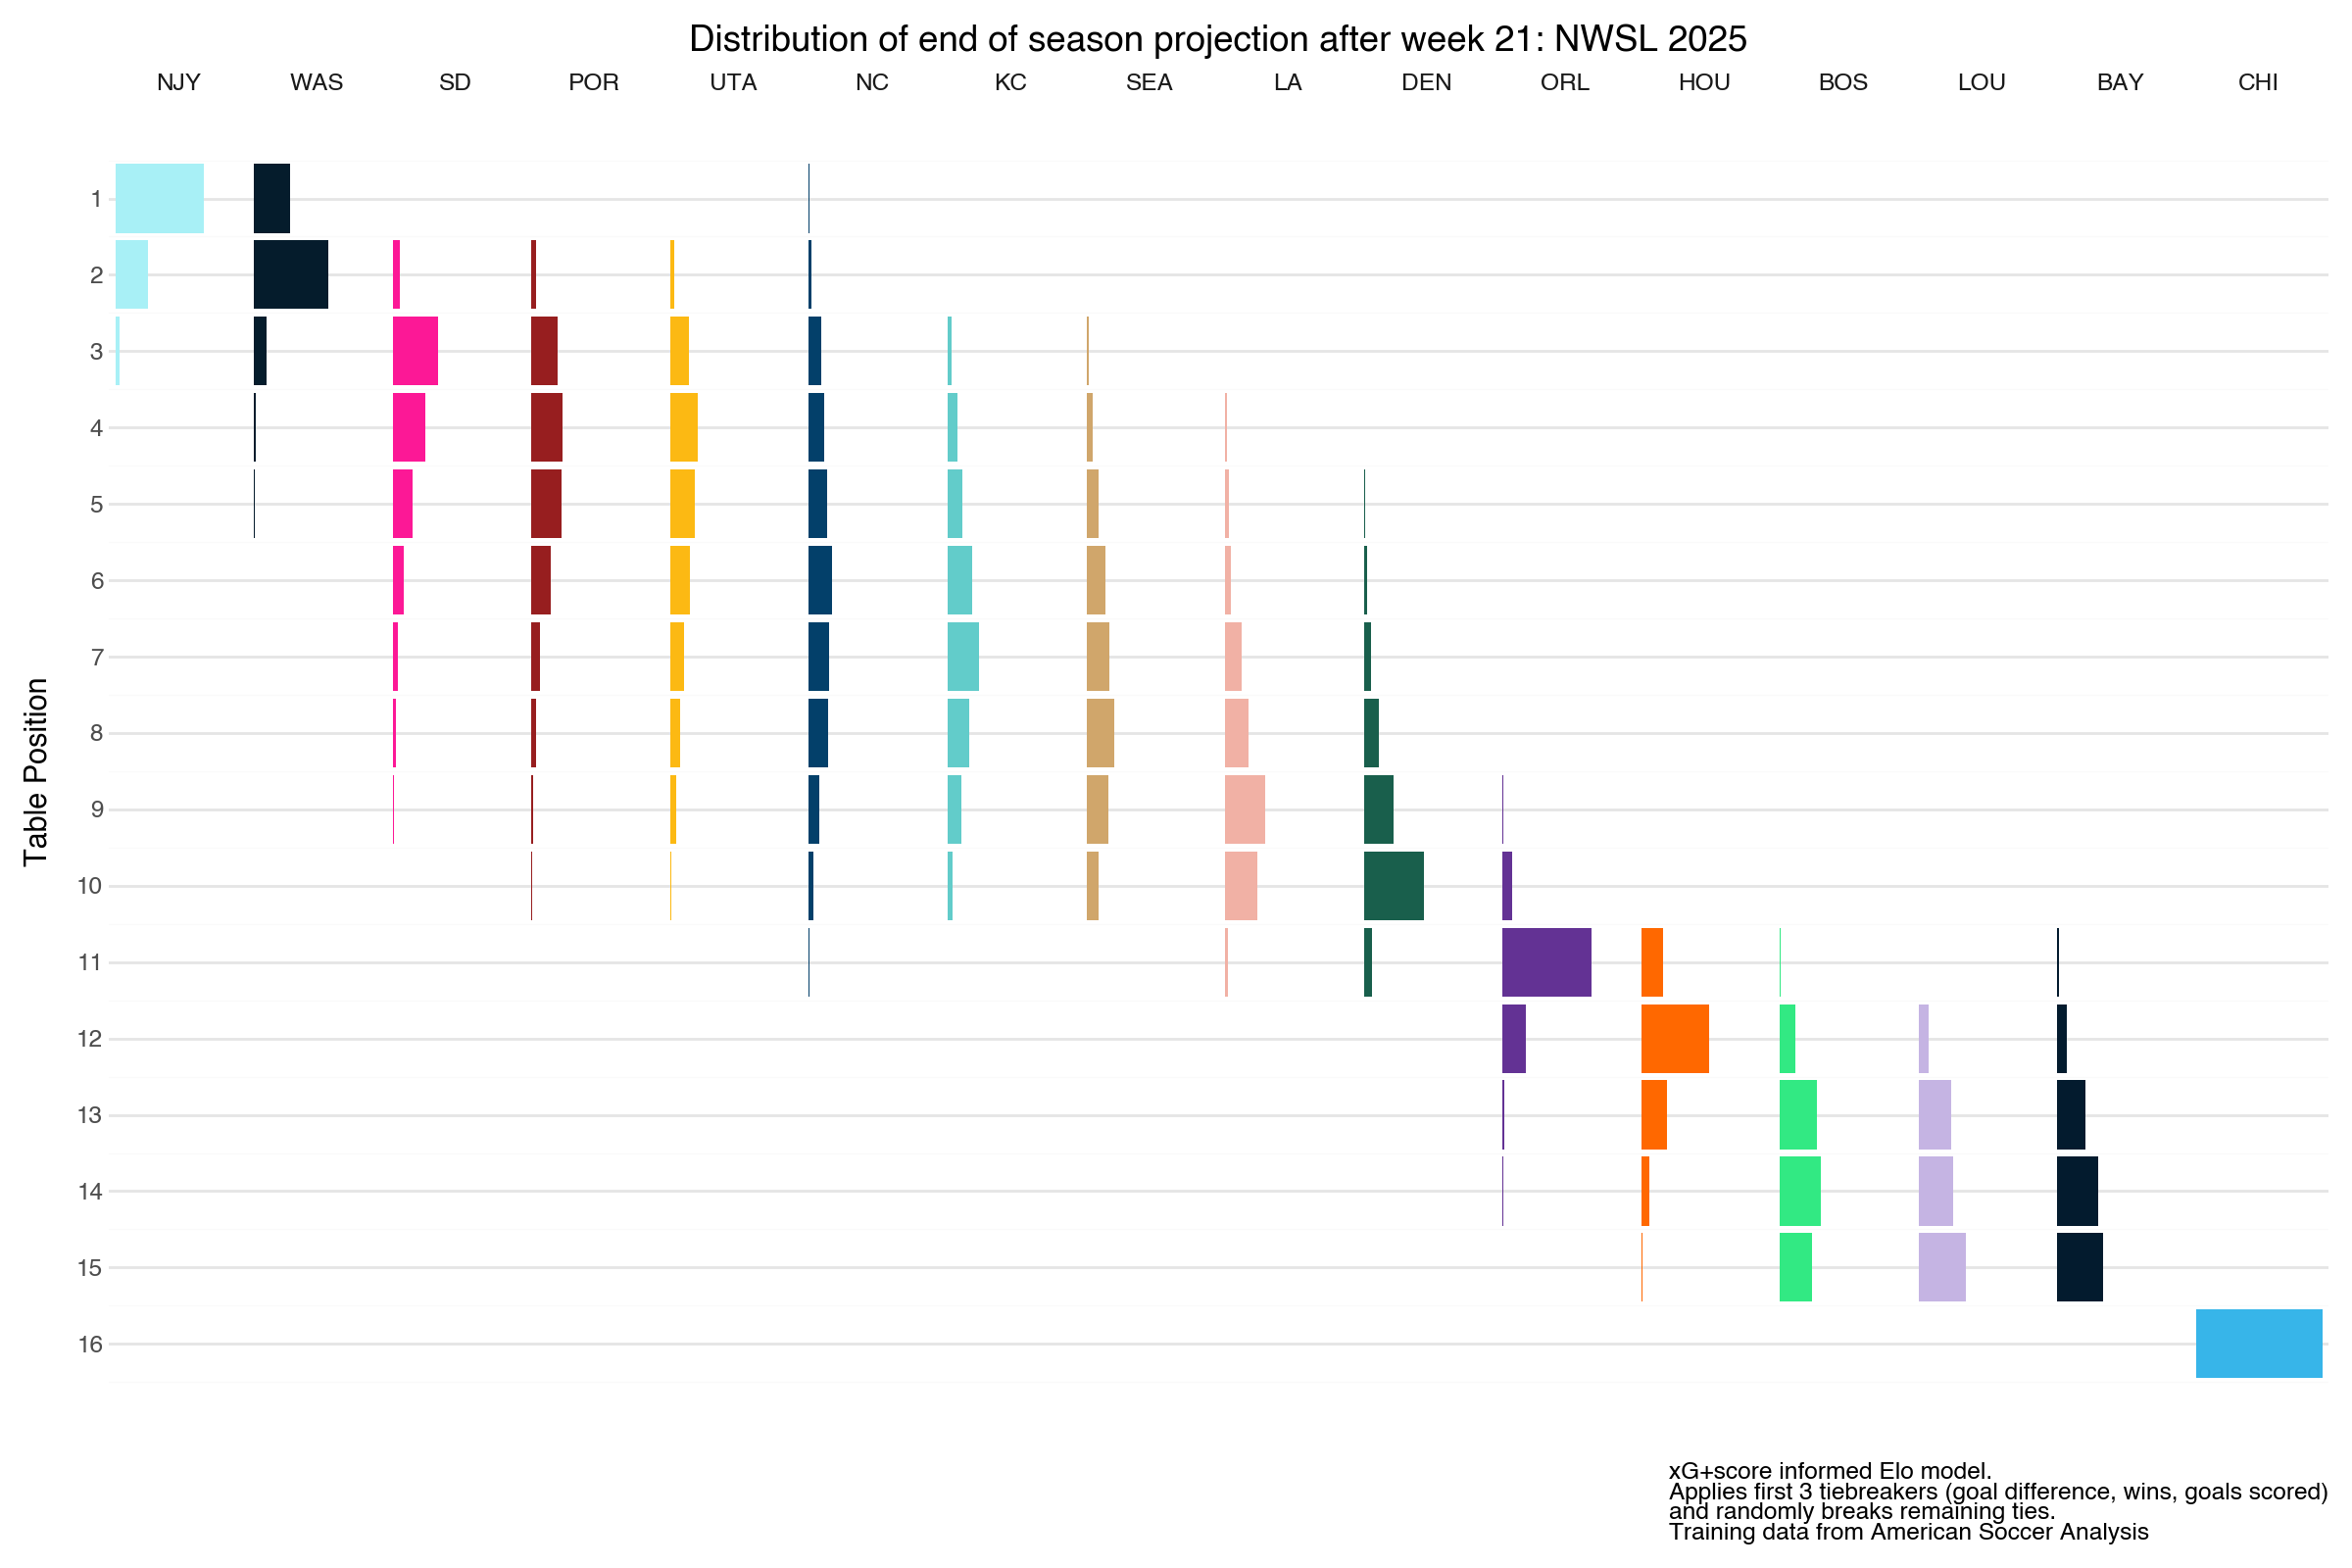

In [31]:
max_count = (
    proj_df.query(f"(matchday == {last_matchday})")
    .groupby(["team", "rank"])
    .points.count()
    .max()
)

(
    ggplot(
        proj_df.query(f"(matchday == {last_matchday})"),
        aes(x="rank", fill="team"),
    )
    + geom_bar()
    + facet_grid("~ team ")
    + scale_fill_manual(nwsl_primary_colors, guide=None)
    + theme_minimal()
    + theme(
        figure_size=(12, 8),
        axis_text_x=element_text(angle=90),
        # plot_margin_left=0,
        panel_spacing=0,
        # panel_spacing_x=-0.003,
    )
    + scale_y_continuous(breaks=False, limits=[0, max_count])
    # + scale_x_continuous(breaks=False)
    + scale_x_reverse(breaks=np.arange(1, 17, 1))
    + coord_flip()
    + labs(
        y="",
        x="Table Position",
        title=f"Distribution of end of season projection after week {last_matchday}: NWSL 2025",
        caption="""xG+score informed Elo model.
Applies first 3 tiebreakers (goal difference, wins, goals scored)
and randomly breaks remaining ties.
Training data from American Soccer Analysis""",
    )
)

In [32]:
params = dict(
    home_points=10, k=6, scaling_factor=100, learn_input="xg+score", goal_diff_draw=0.3
)

games_df = get_games(leagues="nwsl", seasons="2025")


games_df = elo_learn(games_df, **params)

subset_proj_df, hist_df = simulate_season(games_df, num_runs=10000, return_history=True)

In [33]:
subset_proj_df

,team,points,goals_for,wins,goals_against,run_index
0,BAY,20,26,4,41,0
1,CHI,20,32,3,54,0
2,HOU,30,27,8,39,0
3,KC,65,50,21,15,0
4,LA,27,31,7,41,0
...,...,...,...,...,...,...
139995,POR,43,37,12,31,9999
139996,SD,37,41,10,35,9999
139997,SEA,39,32,10,31,9999
139998,UTA,25,28,6,42,9999


In [34]:
subset_proj_df["goal_difference"] = (
    subset_proj_df["goals_for"] - subset_proj_df["goals_against"]
)

# shuffle with new index
subset_proj_df = subset_proj_df.sample(frac=1).reset_index(drop=True)

subset_proj_df["rank"] = subset_proj_df.groupby(["run_index"], group_keys=False)[
    ["points", "goal_difference", "wins", "goals_for"]
].apply(nwsl_rank_func)

subset_proj_df["in_playoff"] = (subset_proj_df["rank"] <= 8).astype(int)

In [35]:
subset_proj_df

,team,points,goals_for,wins,goals_against,run_index,goal_difference,rank,in_playoff
0,SD,37,41,10,35,6719,6,8,1
1,CHI,20,32,3,54,1070,-22,14,0
2,NJY,45,39,12,26,7531,13,3,1
3,NC,35,37,9,39,8688,-2,9,0
4,POR,43,37,12,31,1803,6,5,1
...,...,...,...,...,...,...,...,...,...
139995,LOU,38,36,10,39,6629,-3,7,1
139996,LOU,38,36,10,39,1863,-3,7,1
139997,WAS,49,46,13,36,4018,10,2,1
139998,ORL,44,36,12,29,6384,7,4,1


In [36]:
subset_proj_df.query("team == 'LOU'")["points"].value_counts()

points
38    10000
Name: count, dtype: int64

In [37]:
subset_proj_df.query("team == 'LOU'")["rank"].value_counts()

rank
7    10000
Name: count, dtype: int64

In [38]:
subset_proj_df.query("team == 'LOU'").groupby(["points", "team"]).in_playoff.mean()

points  team
38      LOU     1.0
Name: in_playoff, dtype: float64

In [39]:
subset_proj_df.query("rank == 3").team.value_counts().reset_index()

,team,count
0,NJY,10000


/opt/homebrew/Caskroom/miniconda/base/envs/soph/lib/python3.13/site-packages/plotnine/geoms/geom_path.py:112: PlotnineWarning: geom_path: Each group consist of only one observation. Do you need to adjust the group aesthetic?


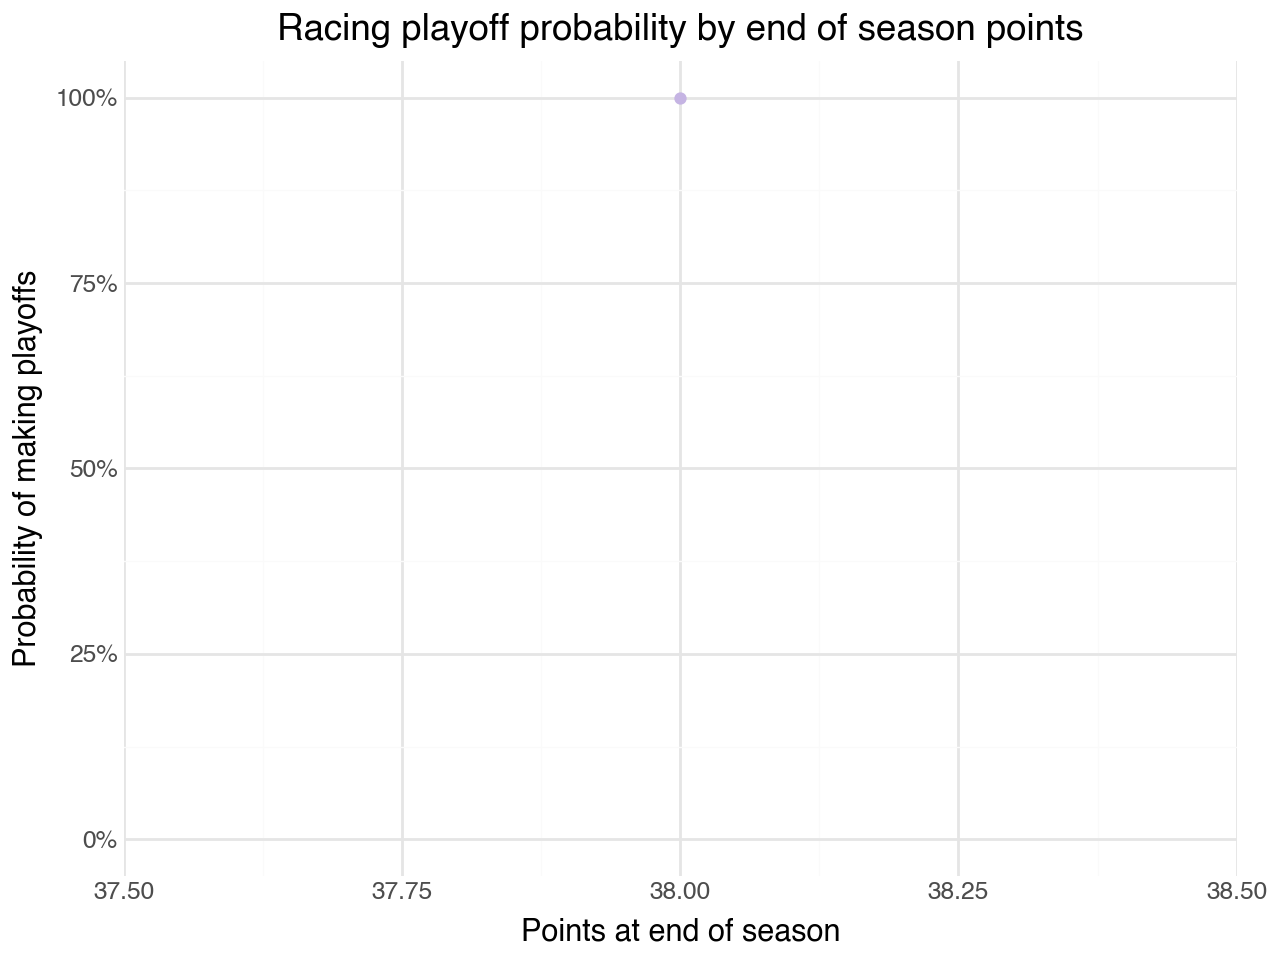

In [40]:
(
    ggplot(
        subset_proj_df.query("team == 'LOU'")
        .groupby(["points", "team"])
        .in_playoff.mean()
        .reset_index(),
        aes(x="points", y="in_playoff", color="team"),
    )
    + geom_point()
    + geom_line()
    + scale_y_continuous(
        limits=[0, 1], labels=lambda breaklist: [f"{x:2.0%}" for x in breaklist]
    )
    + scale_color_manual(nwsl_primary_colors, guide=None)
    + theme_minimal()
    + labs(
        y="Probability of making playoffs",
        x="Points at end of season",
        title="Racing playoff probability by end of season points",
    )
)

In [41]:
hist_df

,game_id,date_time_utc,home_score,away_score,home_team_id,away_team_id,referee_id,stadium_id,home_manager_id,away_manager_id,...,away_rating_pre,home_rating_post,away_rating_post,home_win_prob,draw_prob,home_points,away_points,home_win,away_win,run_index
0,aDQ0b6JW5E,2025-03-08 01:00:00+00:00,1,1,XVqKeVKM01,aDQ0lzvQEv,a35r3kGqL6,vzqoJrj5ap,jYQJJ1VQGR,9YqdzzjMvJ,...,100.000000,102.312260,97.687740,0.457250,0.254245,1,1,0,0,0
1,KXMeZn0X56,2025-03-15 00:00:00+00:00,6,0,XVqKeVKM01,KPqjw8PQ6v,e7MzyK9Qr0,vzqoJrj5ap,jYQJJ1VQGR,2lqRGexQr0,...,100.000000,110.896616,91.415644,0.477458,0.251716,3,0,1,0,0
2,9YqdjO2jMv,2025-03-15 00:00:00+00:00,1,2,4JMAk47qKg,aDQ0lzvQEv,gpMO6A2Qzy,0x5g6ojM7O,KPqjdAEM6v,9YqdzzjMvJ,...,97.687740,96.155150,101.532589,0.477458,0.251716,0,3,0,1,0
3,odMXpkWrMY,2025-03-15 16:45:00+00:00,3,1,4wM4rZdqjB,Pk5LeeNqOW,ljqEmaAqx0,xW5p3L0Mg1,vzqo3mNqap,XVqKEk0M01,...,100.000000,106.640325,93.359675,0.457250,0.254245,3,0,1,0,0
4,NPqxj8dGM9,2025-03-15 23:30:00+00:00,1,1,eV5D2w9QKn,315VnJ759x,KPqj32nQ6v,e7MzlRjqr0,9vQ2YGaqK6,NPqxLwgq9d,...,100.000000,96.312260,103.687740,0.457250,0.254245,1,1,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1899995,NWMWk0beMl,2025-11-09 17:30:00+00:00,1,2,4wM4rZdqjB,raMyrr25d2,NWMWR3DQlz,xW5p3L0Mg1,vzqo3mNqap,9vQ2r1LQK6,...,118.677175,154.014329,124.870627,0.765177,0.163514,0,3,0,1,9999
1899996,0Oq6o6WrQ6,2025-11-09 20:00:00+00:00,1,0,Pk5LeeNqOW,7VqG1lYMvW,315VVZY59x,p6qbX06M0G,XVqKEk0M01,zeQZzPgQKw,...,104.943958,106.809222,102.598975,0.453051,0.254708,3,0,1,0,9999
1899997,gOMnGEN65w,2025-11-15 17:00:00+00:00,2,0,aDQ0lzvQEv,Pk5LeeNqOW,KAqBE1B5bg,xW5pwORMg1,NPqxDAgq9d,XVqKEk0M01,...,106.809222,118.563231,99.038630,0.492003,0.249593,3,0,1,0,9999
1899998,vzqoYEy7Ma,2025-11-16 20:00:00+00:00,0,1,XVqKeVKM01,raMyrr25d2,vzqokJLqap,vzqoJrj5ap,jYQJJ1VQGR,9vQ2r1LQK6,...,124.870627,108.980478,124.067365,0.314696,0.256994,0,3,0,1,9999


In [42]:
games_df.date_time_utc

0     2025-03-08 01:00:00+00:00
1     2025-03-15 00:00:00+00:00
2     2025-03-15 00:00:00+00:00
3     2025-03-15 16:45:00+00:00
4     2025-03-15 23:30:00+00:00
                 ...           
185   2025-11-09 17:30:00+00:00
186   2025-11-09 20:00:00+00:00
187   2025-11-15 17:00:00+00:00
188   2025-11-16 20:00:00+00:00
189   2025-11-23 01:00:00+00:00
Name: date_time_utc, Length: 190, dtype: datetime64[ns, UTC]

In [43]:
games_df.query("matchday == 21").T

,141,142,143,144,145,146,147
game_id,gOMnALRmQw,vzqoKN7jqa,2lqRpdkWMr,wvq9b8gZQW,9z5kjk7lMA,315VpEX6Q9,EGMPadnj5a
date_time_utc,2025-09-19 02:30:00+00:00,2025-09-20 00:00:00+00:00,2025-09-20 00:00:00+00:00,2025-09-20 02:00:00+00:00,2025-09-20 23:30:00+00:00,2025-09-21 02:00:00+00:00,2025-09-22 00:30:00+00:00
home_score,2,0,1,3,2,1,1
away_score,2,1,0,2,0,1,1
home_team_id,kRQa8JOqKZ,XVqKeVKM01,4JMAk47qKg,eV5D2w9QKn,4wM4rZdqjB,Pk5LeeNqOW,315VnJ759x
away_team_id,aDQ0lzvQEv,zeQZeazqKw,KPqjw8PQ6v,eV5DR6YQKn,7vQ7BBzqD1,7VqG1lYMvW,raMyrr25d2
referee_id,BLMvXyjqxe,gpMO6A2Qzy,2vQ1VL4MrA,KAqBp74Mbg,e7MzyK9Qr0,EGMPOOyQaY,KAqBE1B5bg
stadium_id,7vQ7xbOMD1,vzqoJrj5ap,0x5g6ojM7O,e7MzlRjqr0,xW5p3L0Mg1,p6qbX06M0G,Vj58W84M8n
home_manager_id,NWMWPDe5lz,jYQJJ1VQGR,KPqjdAEM6v,9vQ2YGaqK6,vzqo3mNqap,XVqKEk0M01,NPqxLwgq9d
away_manager_id,NPqxDAgq9d,9vQ2PJx5K6,eVq3Y6XMWO,kRQa4GoqKZ,OlMlY7P5Lz,zeQZzPgQKw,9vQ2r1LQK6


In [44]:
lou_df = hist_df.query(
    "((home_team == 'LOU') | (away_team == 'LOU')) & (matchday >= 23)"
)[["home_team", "away_team", "matchday", "home_points", "away_points", "run_index"]]

lou_df["lou_points"] = 0
lou_df.loc[lou_df.home_team == "LOU", "lou_points"] = lou_df.loc[
    lou_df.home_team == "LOU", "home_points"
]
lou_df.loc[lou_df.away_team == "LOU", "lou_points"] = lou_df.loc[
    lou_df.away_team == "LOU", "away_points"
]

lou_df["desc"] = (
    lou_df.home_team + " v " + lou_df.away_team + ": " + lou_df.lou_points.astype(str)
)

lou_df

,home_team,away_team,matchday,home_points,away_points,run_index,lou_points,desc
156,NC,LOU,23,0,3,0,3,NC v LOU: 3
162,LOU,CHI,24,1,1,0,1,LOU v CHI: 1
174,NJY,LOU,25,1,1,0,1,NJY v LOU: 1
178,LOU,BAY,26,3,0,0,3,LOU v BAY: 3
184,WAS,LOU,27,1,1,0,1,WAS v LOU: 1
...,...,...,...,...,...,...,...,...
1899966,NC,LOU,23,0,3,9999,3,NC v LOU: 3
1899972,LOU,CHI,24,1,1,9999,1,LOU v CHI: 1
1899984,NJY,LOU,25,1,1,9999,1,NJY v LOU: 1
1899988,LOU,BAY,26,3,0,9999,3,LOU v BAY: 3


In [45]:
from functools import reduce


def reduce_df(df):
    return reduce(lambda x, y: x + ", " + y, df)

In [46]:
lou_summary = lou_df.groupby("run_index").desc.apply(reduce_df).reset_index(drop=True)

In [47]:
lou_summary.value_counts().head(10)

desc
NC v LOU: 3, LOU v CHI: 1, NJY v LOU: 1, LOU v BAY: 3, WAS v LOU: 1    10000
Name: count, dtype: int64

In [48]:
reduce(lambda x, y: x + ", " + y, lou_df.home_team)

'NC, LOU, NJY, LOU, WAS, NC, LOU, NJY, LOU, WAS, NC, LOU, NJY, LOU, WAS, NC, LOU, NJY, LOU, WAS, NC, LOU, NJY, LOU, WAS, NC, LOU, NJY, LOU, WAS, NC, LOU, NJY, LOU, WAS, NC, LOU, NJY, LOU, WAS, NC, LOU, NJY, LOU, WAS, NC, LOU, NJY, LOU, WAS, NC, LOU, NJY, LOU, WAS, NC, LOU, NJY, LOU, WAS, NC, LOU, NJY, LOU, WAS, NC, LOU, NJY, LOU, WAS, NC, LOU, NJY, LOU, WAS, NC, LOU, NJY, LOU, WAS, NC, LOU, NJY, LOU, WAS, NC, LOU, NJY, LOU, WAS, NC, LOU, NJY, LOU, WAS, NC, LOU, NJY, LOU, WAS, NC, LOU, NJY, LOU, WAS, NC, LOU, NJY, LOU, WAS, NC, LOU, NJY, LOU, WAS, NC, LOU, NJY, LOU, WAS, NC, LOU, NJY, LOU, WAS, NC, LOU, NJY, LOU, WAS, NC, LOU, NJY, LOU, WAS, NC, LOU, NJY, LOU, WAS, NC, LOU, NJY, LOU, WAS, NC, LOU, NJY, LOU, WAS, NC, LOU, NJY, LOU, WAS, NC, LOU, NJY, LOU, WAS, NC, LOU, NJY, LOU, WAS, NC, LOU, NJY, LOU, WAS, NC, LOU, NJY, LOU, WAS, NC, LOU, NJY, LOU, WAS, NC, LOU, NJY, LOU, WAS, NC, LOU, NJY, LOU, WAS, NC, LOU, NJY, LOU, WAS, NC, LOU, NJY, LOU, WAS, NC, LOU, NJY, LOU, WAS, NC, LOU, NJY, L